In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import os

PROJECT_DIR = "/content/drive/MyDrive/ClearSight_Project"

folders = [
    "data/hazy",
    "data/clear",
    "src",
    "results/original",
    "results/dark_channel",
    "results/transmission",
    "results/dehazed",
    "results/comparisons",
    "results/metrics",
    "notebooks"
]

for folder in folders:
    os.makedirs(
        os.path.join(PROJECT_DIR, folder),
        exist_ok=True
    )

print("All project folders created!")
print("Project location:", PROJECT_DIR)

All project folders created!
Project location: /content/drive/MyDrive/ClearSight_Project


In [44]:
from pathlib import Path
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt

PROJECT_DIR = Path(
    "/content/drive/MyDrive/ClearSight_Project"
)

HAZY_DIR = PROJECT_DIR / "data" / "hazy"

DARK_DIR = PROJECT_DIR / "results" / "dark_channel"
DARK_DIR.mkdir(parents=True, exist_ok=True)

# Find all supported image files
image_files = sorted([
    p for p in HAZY_DIR.iterdir()
    if p.suffix.lower() in [
        ".jpg", ".jpeg", ".png", ".bmp"
    ]
])

print("Images found:", len(image_files))

for p in image_files:
    print(p.name)

Images found: 5
haze1.png
haze2.png
haze3.png
haze4.png
haze5.png


Selected image: haze1.png
Image shape: (497, 752, 3)
Minimum intensity: 0.0
Maximum intensity: 0.7176470588235294


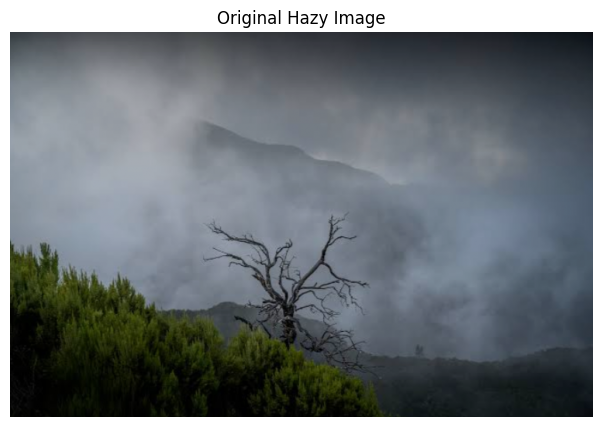

In [45]:
# Select the first image
image_path = image_files[0]

# Read the image and convert it to RGB
original = Image.open(image_path).convert("RGB")

# Convert to a NumPy array and normalize to 0–1
image = np.asarray(
    original,
    dtype=np.float64
) / 255.0

print("Selected image:", image_path.name)
print("Image shape:", image.shape)
print("Minimum intensity:", image.min())
print("Maximum intensity:", image.max())

plt.figure(figsize=(8, 5))
plt.imshow(image)
plt.title("Original Hazy Image")
plt.axis("off")
plt.show()

In [7]:
def calculate_dark_channel(image, window_size=15):

    # Step 1: Find the minimum RGB value at each pixel
    min_rgb = np.min(image, axis=2)

    # Step 2: Calculate padding for the local window
    pad = window_size // 2

    # Step 3: Pad the image boundaries
    padded = np.pad(
        min_rgb,
        ((pad, pad), (pad, pad)),
        mode="edge"
    )

    # Step 4: Get image height and width
    height, width = min_rgb.shape

    # Step 5: Initialize the dark channel
    dark = np.ones(
        (height, width),
        dtype=np.float64
    )

    # Step 6: Find the minimum value in each local window
    for dy in range(window_size):
        for dx in range(window_size):

            region = padded[
                dy:dy + height,
                dx:dx + width
            ]

            dark = np.minimum(dark, region)

    # Step 7: Return the completed dark channel
    return dark

Original image shape: (497, 752, 3)
Dark channel shape: (497, 752)
Dark channel minimum: 0.0
Dark channel maximum: 0.6470588235294118


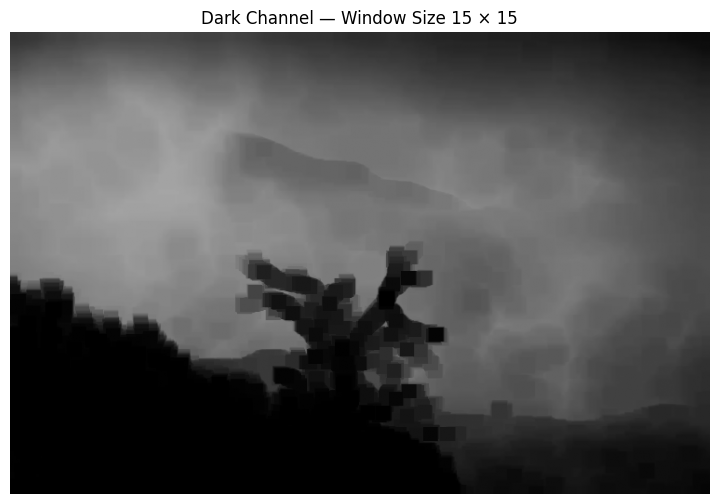

In [8]:
dark_channel = calculate_dark_channel(
    image,
    window_size=15
)

print("Original image shape:", image.shape)
print("Dark channel shape:", dark_channel.shape)
print("Dark channel minimum:", dark_channel.min())
print("Dark channel maximum:", dark_channel.max())

plt.figure(figsize=(10, 6))
plt.imshow(
    dark_channel,
    cmap="gray",
    vmin=0,
    vmax=1
)
plt.title("Dark Channel — Window Size 15 × 15")
plt.axis("off")
plt.show()

In [9]:
# Convert normalized intensity to 8-bit grayscale
dark_uint8 = np.uint8(
    np.clip(dark_channel, 0, 1) * 255
)

# Create an output filename
output_path = DARK_DIR / (
    image_path.stem + "_dark_channel.png"
)

# Save directly to Google Drive
Image.fromarray(dark_uint8).save(output_path)

print("Dark channel saved successfully!")
print("Saved location:", output_path)

Dark channel saved successfully!
Saved location: /content/drive/MyDrive/ClearSight_Project/results/dark_channel/haze1_dark_channel.png


In [10]:
from pathlib import Path
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt

PROJECT_DIR = Path(
    "/content/drive/MyDrive/ClearSight_Project"
)

HAZY_DIR = PROJECT_DIR / "data" / "hazy"
DARK_DIR = PROJECT_DIR / "results" / "dark_channel"

DARK_DIR.mkdir(parents=True, exist_ok=True)

# Find all input images
image_files = sorted([
    p for p in HAZY_DIR.iterdir()
    if p.suffix.lower() in
    [".jpg", ".jpeg", ".png", ".bmp"]
])

print("Total input images:", len(image_files))

# Process every image
for image_path in image_files:

    # Read and normalize the image
    original = Image.open(image_path).convert("RGB")
    image = np.asarray(
        original, dtype=np.float64
    ) / 255.0

    # Calculate dark channel using your Step 5 function
    dark = calculate_dark_channel(
        image,
        window_size=15
    )

    # Convert to grayscale format
    dark_uint8 = np.uint8(
        np.clip(dark, 0, 1) * 255
    )

    # Save the output to Google Drive
    output_path = DARK_DIR / (
        image_path.stem + "_dark_channel.png"
    )

    Image.fromarray(dark_uint8).save(output_path)

    print("Processed:", image_path.name)
    print("Saved:", output_path.name)

print("\nAll images processed successfully!")

Total input images: 5
Processed: haze1.png
Saved: haze1_dark_channel.png
Processed: haze2.png
Saved: haze2_dark_channel.png
Processed: haze3.png
Saved: haze3_dark_channel.png
Processed: haze4.png
Saved: haze4_dark_channel.png
Processed: haze5.png
Saved: haze5_dark_channel.png

All images processed successfully!


In [11]:
from pathlib import Path

PROJECT_DIR = Path(
    "/content/drive/MyDrive/ClearSight_Project"
)

HAZY_DIR = PROJECT_DIR / "data" / "hazy"
DARK_DIR = PROJECT_DIR / "results" / "dark_channel"

ATMOS_DIR = PROJECT_DIR / "results" / "atmospheric_light"
ATMOS_DIR.mkdir(parents=True, exist_ok=True)

print("Atmospheric light output folder is ready!")

Atmospheric light output folder is ready!


In [12]:
import numpy as np

def estimate_atmospheric_light(
    image,
    dark_channel,
    top_fraction=0.001
):
    # Step 1: Get image dimensions
    height, width = dark_channel.shape

    # Step 2: Select the number of candidate pixels
    total_pixels = height * width
    count = max(
        1,
        int(total_pixels * top_fraction)
    )

    # Step 3: Flatten the dark-channel map
    dark_flat = dark_channel.ravel()

    # Step 4: Find pixels with the highest dark values
    candidates = np.argpartition(
        dark_flat,
        -count
    )[-count:]

    # Step 5: Flatten the original RGB image
    rgb_flat = image.reshape(-1, 3)

    # Step 6: Calculate average RGB intensity
    brightness = rgb_flat[candidates].mean(axis=1)

    # Step 7: Select the brightest candidate
    best_index = candidates[np.argmax(brightness)]

    # Step 8: Return its original RGB values
    atmospheric_light = rgb_flat[best_index]

    return atmospheric_light

In [13]:
from PIL import Image
import csv

image_files = sorted([
    p for p in HAZY_DIR.iterdir()
    if p.suffix.lower() in [
        ".jpg", ".jpeg", ".png", ".bmp"
    ]
])

results = []

for image_path in image_files:

    # Load the original hazy image
    original = Image.open(image_path).convert("RGB")

    image = np.asarray(
        original,
        dtype=np.float64
    ) / 255.0

    # Load the dark channel saved in Step 5
    dark_path = DARK_DIR / (
        image_path.stem + "_dark_channel.png"
    )

    if not dark_path.exists():
        print("Dark channel not found:", image_path.name)
        continue

    dark = np.asarray(
        Image.open(dark_path).convert("L"),
        dtype=np.float64
    ) / 255.0

    # Check that both images have matching dimensions
    if dark.shape != image.shape[:2]:
        print("Dimension mismatch:", image_path.name)
        continue

    # Estimate atmospheric light
    A = estimate_atmospheric_light(image, dark)

    # Store the results
    results.append([
        image_path.name,
        float(A[0]),
        float(A[1]),
        float(A[2])
    ])

    print(
        f"{image_path.name}: "
        f"R={A[0]:.4f}, "
        f"G={A[1]:.4f}, "
        f"B={A[2]:.4f}"
    )

# Save all estimates permanently in Google Drive
csv_path = ATMOS_DIR / "atmospheric_light_values.csv"

with open(csv_path, "w", newline="") as file:
    writer = csv.writer(file)

    writer.writerow([
        "Image",
        "Atmospheric_R",
        "Atmospheric_G",
        "Atmospheric_B"
    ])

    writer.writerows(results)

print("\nCompleted atmospheric-light estimation!")
print("Images processed:", len(results))
print("Results saved to:", csv_path)

haze1.png: R=0.6549, G=0.6784, B=0.7098
haze2.png: R=0.9569, G=0.9569, B=0.9569
haze3.png: R=0.7020, G=0.7216, B=0.7020
haze4.png: R=0.9373, G=0.9412, B=0.9529
haze5.png: R=0.7765, G=0.7569, B=0.7294

Completed atmospheric-light estimation!
Images processed: 5
Results saved to: /content/drive/MyDrive/ClearSight_Project/results/atmospheric_light/atmospheric_light_values.csv


In [14]:
from pathlib import Path

PROJECT_DIR = Path(
    "/content/drive/MyDrive/ClearSight_Project"
)

HAZY_DIR = PROJECT_DIR / "data" / "hazy"
DARK_DIR = PROJECT_DIR / "results" / "dark_channel"

ATMOS_DIR = PROJECT_DIR / "results" / "atmospheric_light"

TRANS_DIR = PROJECT_DIR / "results" / "transmission"
TRANS_DIR.mkdir(parents=True, exist_ok=True)

print("Transmission output folder created!")

Transmission output folder created!


In [15]:
import numpy as np

def estimate_transmission(
    image,
    atmospheric_light,
    omega=0.95,
    window_size=15
):
    # Step 1: Avoid division by zero
    safe_A = np.maximum(atmospheric_light, 1e-6)

    # Step 2: Normalize the RGB image by atmospheric light
    normalized = image / safe_A

    # Step 3: Calculate the dark channel of the normalized image
    dark_normalized = calculate_dark_channel(
        normalized,
        window_size=window_size
    )

    # Step 4: Estimate transmission
    transmission = 1 - omega * dark_normalized

    # Step 5: Keep transmission within the range 0–1
    transmission = np.clip(transmission, 0, 1)

    return transmission

In [16]:
from PIL import Image
import csv

# Load the atmospheric-light estimates from Step 6
csv_path = ATMOS_DIR / "atmospheric_light_values.csv"

atmospheric_values = {}

with open(csv_path, "r", newline="") as file:
    reader = csv.DictReader(file)

    for row in reader:
        atmospheric_values[row["Image"]] = np.array([
            float(row["Atmospheric_R"]),
            float(row["Atmospheric_G"]),
            float(row["Atmospheric_B"])
        ])

image_files = sorted([
    p for p in HAZY_DIR.iterdir()
    if p.suffix.lower() in [
        ".jpg", ".jpeg", ".png", ".bmp"
    ]
])

transmission_results = []

for image_path in image_files:

    image = np.asarray(
        Image.open(image_path).convert("RGB"),
        dtype=np.float64
    ) / 255.0

    if image_path.name not in atmospheric_values:
        print("Missing atmospheric light:", image_path.name)
        continue

    A = atmospheric_values[image_path.name]
    transmission = estimate_transmission(
        image,
        A,
        omega=0.95,
        window_size=15
    )
    output_path = TRANS_DIR / (
        image_path.stem + "_transmission.png"
    )

    transmission_uint8 = np.uint8(
        np.clip(transmission, 0, 1) * 255
    )

    Image.fromarray(transmission_uint8).save(output_path)

    transmission_results.append([
        image_path.name,
        float(transmission.min()),
        float(transmission.max()),
        float(transmission.mean())
    ])

    print("Processed:", image_path.name)
    print("Saved:", output_path.name)
    print("Transmission range:",
          round(float(transmission.min()), 4),
          "to",
          round(float(transmission.max()), 4))

summary_path = TRANS_DIR / "transmission_summary.csv"

with open(summary_path, "w", newline="") as file:
    writer = csv.writer(file)

    writer.writerow([
        "Image",
        "Minimum_Transmission",
        "Maximum_Transmission",
        "Mean_Transmission"
    ])

    writer.writerows(transmission_results)

print("\nTransmission estimation completed!")
print("Images processed:", len(transmission_results))
print("Summary saved:", summary_path)

Processed: haze1.png
Saved: haze1_transmission.png
Transmission range: 0.0614 to 1.0
Processed: haze2.png
Saved: haze2_transmission.png
Transmission range: 0.0539 to 1.0
Processed: haze3.png
Saved: haze3_transmission.png
Transmission range: 0.05 to 0.9628
Processed: haze4.png
Saved: haze4_transmission.png
Transmission range: 0.1255 to 0.7973
Processed: haze5.png
Saved: haze5_transmission.png
Transmission range: 0.0755 to 1.0

Transmission estimation completed!
Images processed: 5
Summary saved: /content/drive/MyDrive/ClearSight_Project/results/transmission/transmission_summary.csv


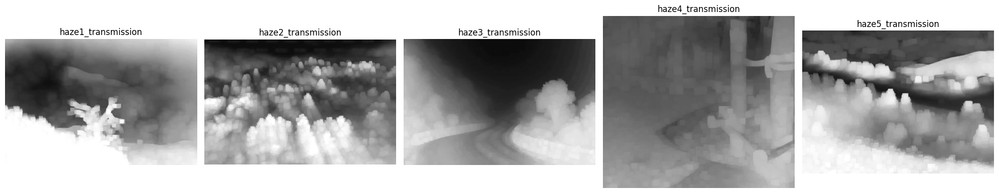

In [17]:
import matplotlib.pyplot as plt

saved_maps = sorted(
    TRANS_DIR.glob("*_transmission.png")
)

fig, axes = plt.subplots(
    1, len(saved_maps),
    figsize=(4 * len(saved_maps), 4)
)

if len(saved_maps) == 1:
    axes = [axes]

for ax, path in zip(axes, saved_maps):
    transmission_image = Image.open(path).convert("L")

    ax.imshow(
        transmission_image,
        cmap="gray",
        vmin=0,
        vmax=255
    )
    ax.set_title(path.stem)
    ax.axis("off")

plt.tight_layout()
plt.show()

In [19]:
from pathlib import Path

PROJECT_DIR = Path(
    "/content/drive/MyDrive/ClearSight_Project"
)

HAZY_DIR = PROJECT_DIR / "data" / "hazy"
ATMOS_DIR = PROJECT_DIR / "results" / "atmospheric_light"
TRANS_DIR = PROJECT_DIR / "results" / "transmission"

DEHAZED_DIR = PROJECT_DIR / "results" / "dehazed"
DEHAZED_DIR.mkdir(parents=True, exist_ok=True)

print("Dehazed output folder is ready!")

Dehazed output folder is ready!


In [20]:
import numpy as np

def reconstruct_dehazed_image(
    image,
    atmospheric_light,
    transmission,
    t0=0.1
):
    safe_transmission = np.maximum(
        transmission, t0
    )[..., None]

    dehazed = (
        (image - atmospheric_light)
        / safe_transmission
        + atmospheric_light
    )

    dehazed = np.clip(dehazed, 0, 1)

    return dehazed

In [21]:
from PIL import Image
import csv

atmos_csv = ATMOS_DIR / "atmospheric_light_values.csv"

atmospheric_values = {}

with open(atmos_csv, "r", newline="") as file:
    reader = csv.DictReader(file)

    for row in reader:
        atmospheric_values[row["Image"]] = np.array([
            float(row["Atmospheric_R"]),
            float(row["Atmospheric_G"]),
            float(row["Atmospheric_B"])
        ])

image_files = sorted([
    p for p in HAZY_DIR.iterdir()
    if p.suffix.lower() in [
        ".jpg", ".jpeg", ".png", ".bmp"
    ]
])

processed_count = 0

for image_path in image_files:

    image = np.asarray(
        Image.open(image_path).convert("RGB"),
        dtype=np.float64
    ) / 255.0

    if image_path.name not in atmospheric_values:
        print("Missing atmospheric light:", image_path.name)
        continue

    A = atmospheric_values[image_path.name]

    transmission_path = TRANS_DIR / (
        image_path.stem + "_transmission.png"
    )

    if not transmission_path.exists():
        print("Missing transmission map:", image_path.name)
        continue

    transmission = np.asarray(
        Image.open(transmission_path).convert("L"),
        dtype=np.float64
    ) / 255.0

    if transmission.shape != image.shape[:2]:
        print("Dimension mismatch:", image_path.name)
        continue
    dehazed = reconstruct_dehazed_image(
        image,
        A,
        transmission,
        t0=0.1
    )

    output_path = DEHAZED_DIR / (
        image_path.stem + "_dehazed.png"
    )

    output_uint8 = np.uint8(
        np.clip(dehazed, 0, 1) * 255
    )

    Image.fromarray(output_uint8).save(output_path)

    processed_count += 1
    print("Saved:", output_path.name)

print("\nReconstruction completed!")
print("Images processed:", processed_count)

Saved: haze1_dehazed.png
Saved: haze2_dehazed.png
Saved: haze3_dehazed.png
Saved: haze4_dehazed.png
Saved: haze5_dehazed.png

Reconstruction completed!
Images processed: 5


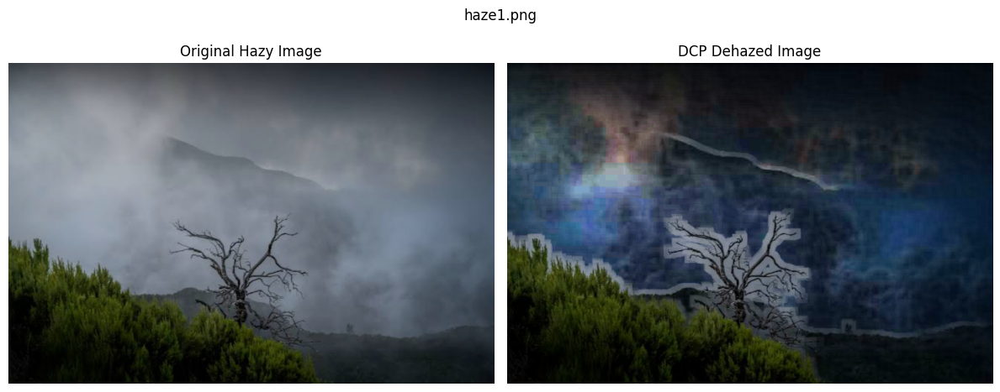

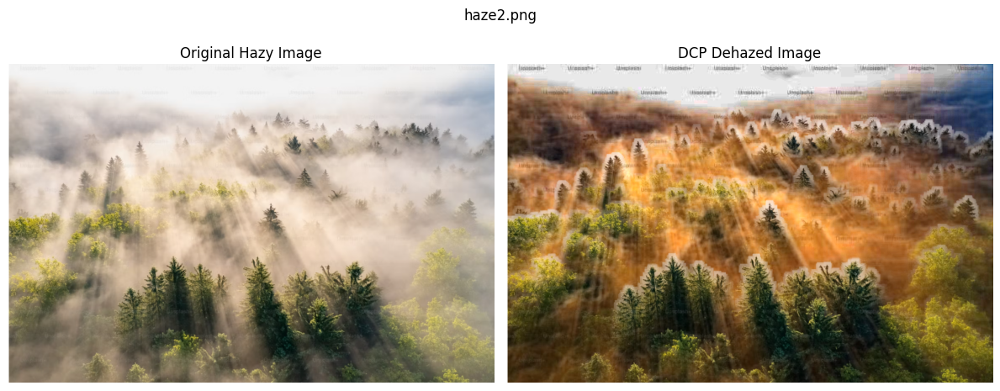

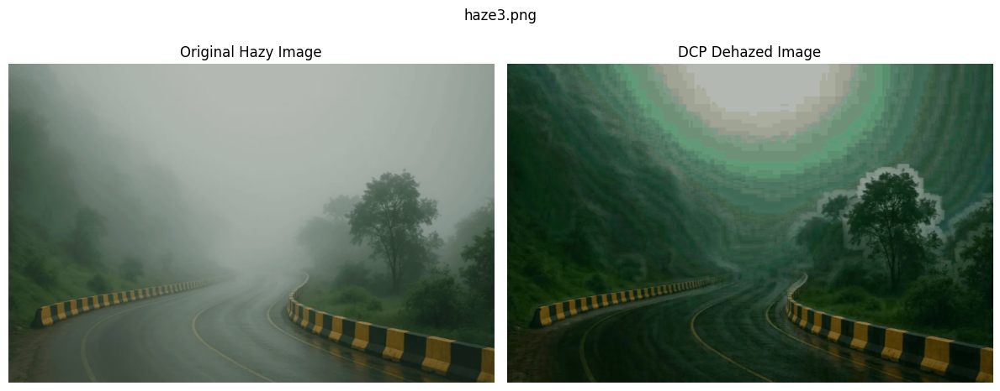

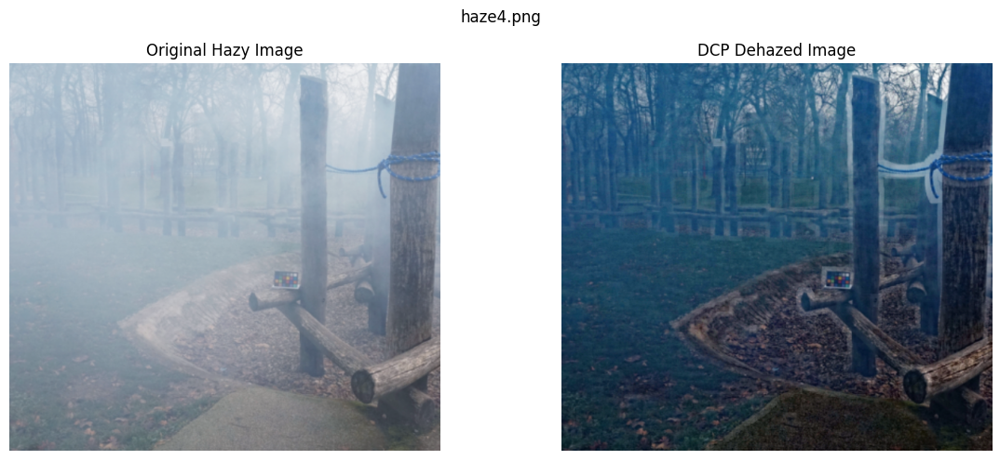

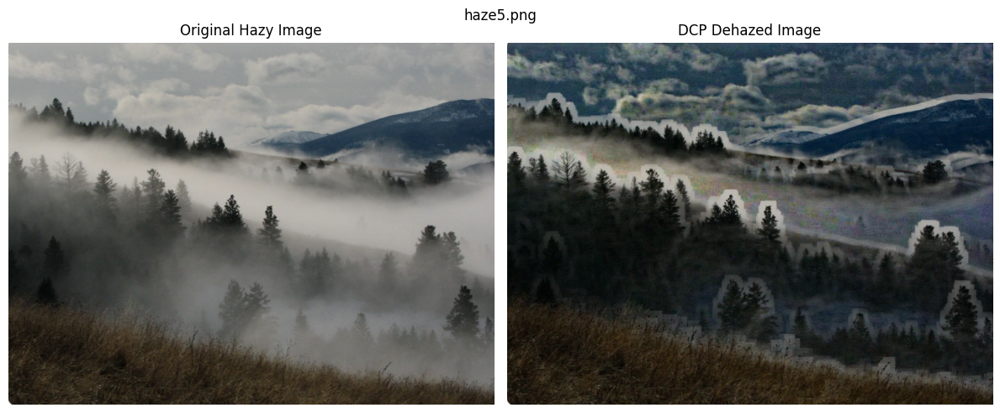

In [22]:
import matplotlib.pyplot as plt

for image_path in image_files:

    output_path = DEHAZED_DIR / (
        image_path.stem + "_dehazed.png"
    )

    if not output_path.exists():
        continue

    original = Image.open(image_path).convert("RGB")
    result = Image.open(output_path).convert("RGB")

    fig, axes = plt.subplots(1, 2, figsize=(12, 5))

    axes[0].imshow(original)
    axes[0].set_title("Original Hazy Image")

    axes[1].imshow(result)
    axes[1].set_title("DCP Dehazed Image")

    for ax in axes:
        ax.axis("off")

    plt.suptitle(image_path.name)
    plt.tight_layout()
    plt.show()

In [23]:
from pathlib import Path

PROJECT_DIR = Path("/content/drive/MyDrive/ClearSight_Project")
TRANS_DIR = PROJECT_DIR / "results" / "transmission"
REFINED_DIR = PROJECT_DIR / "results" / "refined_transmission"
DEHAZED_DIR = PROJECT_DIR / "results" / "dehazed"

REFINED_DIR.mkdir(parents=True, exist_ok=True)

print("Refined transmission folder created.")

Refined transmission folder created.


In [24]:
import numpy as np

def refine_transmission(transmission, window_size=5):
    if window_size % 2 == 0:
        raise ValueError("Window size must be odd.")

    pad = window_size // 2

    padded = np.pad(
        transmission,
        ((pad, pad), (pad, pad)),
        mode="edge"
    )

    height, width = transmission.shape
    refined = np.zeros_like(transmission, dtype=np.float64)

    for dy in range(window_size):
        for dx in range(window_size):
            region = padded[
                dy:dy + height,
                dx:dx + width
            ]
            refined += region

    refined /= window_size ** 2

    return np.clip(refined, 0, 1)

In [25]:
from PIL import Image
import matplotlib.pyplot as plt

image_files = sorted([
    p for p in (PROJECT_DIR / "data" / "hazy").iterdir()
    if p.suffix.lower() in [".jpg", ".jpeg", ".png", ".bmp"]
])

for image_path in image_files:
    trans_path = TRANS_DIR / f"{image_path.stem}_transmission.png"

    if not trans_path.exists():
        print("Missing:", trans_path.name)
        continue

    transmission = np.asarray(
        Image.open(trans_path).convert("L"),
        dtype=np.float64
    ) / 255.0

    refined = refine_transmission(transmission, window_size=5)

    output_path = REFINED_DIR / f"{image_path.stem}_refined.png"

    Image.fromarray(
        np.uint8(np.clip(refined, 0, 1) * 255)
    ).save(output_path)

    print("Saved:", output_path.name)

Saved: haze1_refined.png
Saved: haze2_refined.png
Saved: haze3_refined.png
Saved: haze4_refined.png
Saved: haze5_refined.png


In [26]:
import csv

ATMOS_DIR = PROJECT_DIR / "results" / "atmospheric_light"
DEHAZED_DIR = PROJECT_DIR / "results" / "dehazed"

with open(ATMOS_DIR / "atmospheric_light_values.csv", "r", newline="") as file:
    atmospheric_values = {
        row["Image"]: np.array([
            float(row["Atmospheric_R"]),
            float(row["Atmospheric_G"]),
            float(row["Atmospheric_B"])
        ])
        for row in csv.DictReader(file)
    }

for image_path in image_files:
    refined_path = REFINED_DIR / f"{image_path.stem}_refined.png"

    if image_path.name not in atmospheric_values or not refined_path.exists():
        print("Skipped:", image_path.name)
        continue

    image = np.asarray(
        Image.open(image_path).convert("RGB"),
        dtype=np.float64
    ) / 255.0

    refined = np.asarray(
        Image.open(refined_path).convert("L"),
        dtype=np.float64
    ) / 255.0

    A = atmospheric_values[image_path.name]

    dehazed_refined = reconstruct_dehazed_image(
        image,
        A,
        refined,
        t0=0.1
    )

    output_path = DEHAZED_DIR / f"{image_path.stem}_dehazed_refined.png"

    Image.fromarray(
        np.uint8(np.clip(dehazed_refined, 0, 1) * 255)
    ).save(output_path)

    print("Saved:", output_path.name)

Saved: haze1_dehazed_refined.png
Saved: haze2_dehazed_refined.png
Saved: haze3_dehazed_refined.png
Saved: haze4_dehazed_refined.png
Saved: haze5_dehazed_refined.png


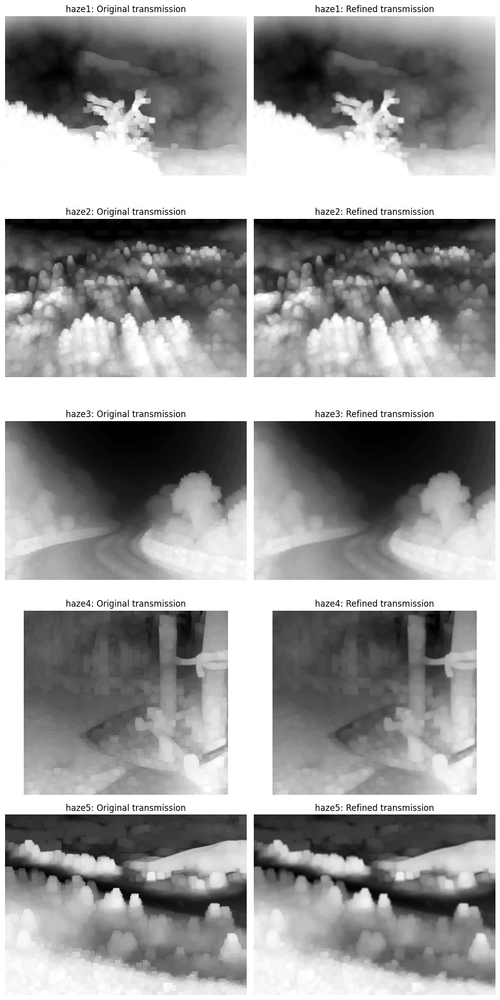

In [27]:
fig, axes = plt.subplots(len(image_files), 2, figsize=(10, 4 * len(image_files)))

if len(image_files) == 1:
    axes = np.array([axes])

for i, image_path in enumerate(image_files):
    original_path = TRANS_DIR / f"{image_path.stem}_transmission.png"
    refined_path = REFINED_DIR / f"{image_path.stem}_refined.png"

    if not original_path.exists() or not refined_path.exists():
        axes[i, 0].axis("off")
        axes[i, 1].axis("off")
        continue

    axes[i, 0].imshow(Image.open(original_path).convert("L"), cmap="gray")
    axes[i, 0].set_title(f"{image_path.stem}: Original transmission")

    axes[i, 1].imshow(Image.open(refined_path).convert("L"), cmap="gray")
    axes[i, 1].set_title(f"{image_path.stem}: Refined transmission")

    axes[i, 0].axis("off")
    axes[i, 1].axis("off")

plt.tight_layout()
plt.show()

In [28]:
from pathlib import Path

PROJECT_DIR = Path("/content/drive/MyDrive/ClearSight_Project")

CONTRAST_DIR = PROJECT_DIR / "results" / "contrast_stretching"
GAMMA_DIR = PROJECT_DIR / "results" / "gamma_correction"

CONTRAST_DIR.mkdir(parents=True, exist_ok=True)
GAMMA_DIR.mkdir(parents=True, exist_ok=True)

print("Baseline output folders are ready.")

Baseline output folders are ready.


In [29]:
import numpy as np

def contrast_stretch(image):
    low = image.min()
    high = image.max()

    if high <= low:
        return image.copy()

    return np.clip((image - low) / (high - low), 0, 1)

In [31]:
def gamma_correction(image, gamma=0.8):
    return np.clip(image, 0, 1) ** gamma

In [32]:
from PIL import Image

HAZY_DIR = PROJECT_DIR / "data" / "hazy"

image_files = sorted([
    p for p in HAZY_DIR.iterdir()
    if p.suffix.lower() in [".jpg", ".jpeg", ".png", ".bmp"]
])

for image_path in image_files:
    image = np.asarray(
        Image.open(image_path).convert("RGB"),
        dtype=np.float64
    ) / 255.0

    contrast_result = contrast_stretch(image)
    gamma_result = gamma_correction(image, gamma=0.8)

    contrast_path = CONTRAST_DIR / f"{image_path.stem}_contrast.png"
    gamma_path = GAMMA_DIR / f"{image_path.stem}_gamma.png"

    Image.fromarray(
        np.uint8(np.clip(contrast_result, 0, 1) * 255)
    ).save(contrast_path)

    Image.fromarray(
        np.uint8(np.clip(gamma_result, 0, 1) * 255)
    ).save(gamma_path)

    print("Processed:", image_path.name)

print("All baseline results saved.")

Processed: haze1.png
Processed: haze2.png
Processed: haze3.png
Processed: haze4.png
Processed: haze5.png
All baseline results saved.


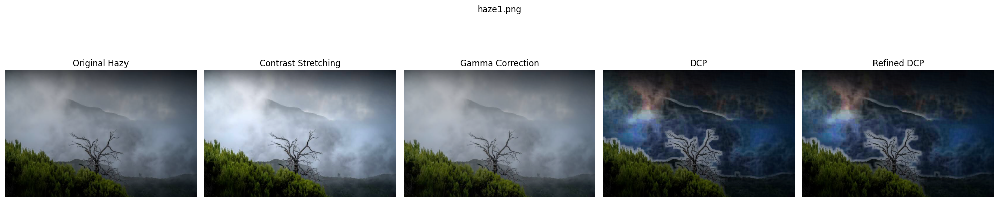

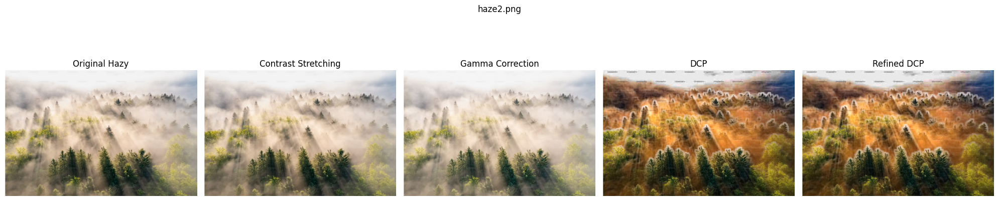

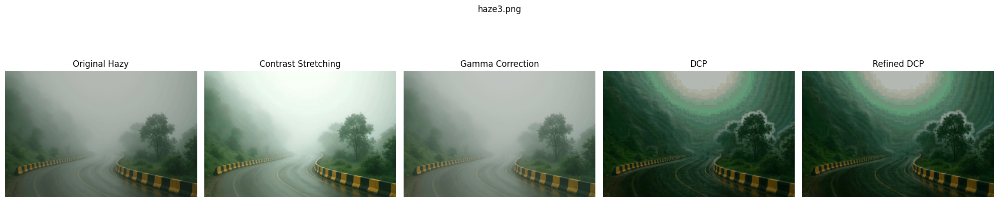

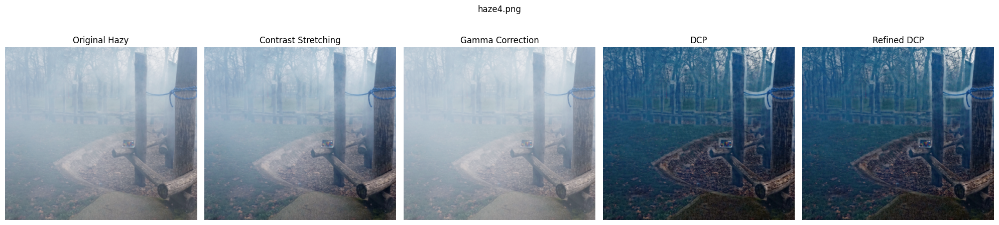

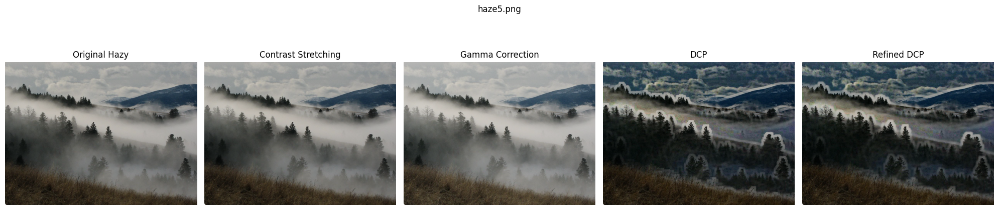

In [33]:
import matplotlib.pyplot as plt

DEHAZED_DIR = PROJECT_DIR / "results" / "dehazed"

for image_path in image_files:
    paths = [
        image_path,
        CONTRAST_DIR / f"{image_path.stem}_contrast.png",
        GAMMA_DIR / f"{image_path.stem}_gamma.png",
        DEHAZED_DIR / f"{image_path.stem}_dehazed.png",
        DEHAZED_DIR / f"{image_path.stem}_dehazed_refined.png"
    ]

    titles = [
        "Original Hazy",
        "Contrast Stretching",
        "Gamma Correction",
        "DCP",
        "Refined DCP"
    ]

    fig, axes = plt.subplots(1, 5, figsize=(20, 5))

    for ax, path, title in zip(axes, paths, titles):
        if path.exists():
            ax.imshow(Image.open(path).convert("RGB"))
            ax.set_title(title)
        else:
            ax.set_title(f"{title}\nOutput missing")

        ax.axis("off")

    plt.suptitle(image_path.name)
    plt.tight_layout()
    plt.show()

In [36]:
from pathlib import Path

PROJECT_DIR = Path("/content/drive/MyDrive/ClearSight_Project")

METRICS_DIR = PROJECT_DIR / "results" / "metrics"
COMPARISON_DIR = PROJECT_DIR / "results" / "comparisons"

METRICS_DIR.mkdir(parents=True, exist_ok=True)
COMPARISON_DIR.mkdir(parents=True, exist_ok=True)

print("Evaluation folders are ready.")

Evaluation folders are ready.


In [37]:
import numpy as np

def calculate_image_metrics(image):
    gray = (
        0.299 * image[:, :, 0]
        + 0.587 * image[:, :, 1]
        + 0.114 * image[:, :, 2]
    )

    return {
        "Mean_Brightness": float(np.mean(gray)),
        "Contrast_Std": float(np.std(gray))
    }

In [38]:
from PIL import Image
import csv
import time

HAZY_DIR = PROJECT_DIR / "data" / "hazy"
TRANS_DIR = PROJECT_DIR / "results" / "transmission"
REFINED_DIR = PROJECT_DIR / "results" / "refined_transmission"
DEHAZED_DIR = PROJECT_DIR / "results" / "dehazed"
CONTRAST_DIR = PROJECT_DIR / "results" / "contrast_stretching"
GAMMA_DIR = PROJECT_DIR / "results" / "gamma_correction"

image_files = sorted([
    p for p in HAZY_DIR.iterdir()
    if p.suffix.lower() in [".jpg", ".jpeg", ".png", ".bmp"]
])

evaluation_rows = []

for image_path in image_files:
    original = np.asarray(
        Image.open(image_path).convert("RGB"),
        dtype=np.float64
    ) / 255.0

    methods = [
        ("Original", image_path),
        ("Contrast Stretching", CONTRAST_DIR / f"{image_path.stem}_contrast.png"),
        ("Gamma Correction", GAMMA_DIR / f"{image_path.stem}_gamma.png"),
        ("DCP", DEHAZED_DIR / f"{image_path.stem}_dehazed.png"),
        ("Refined DCP", DEHAZED_DIR / f"{image_path.stem}_dehazed_refined.png")
    ]

    for method, output_path in methods:
        if not output_path.exists():
            print("Missing output:", output_path.name)
            continue

        start = time.perf_counter()

        result = np.asarray(
            Image.open(output_path).convert("RGB"),
            dtype=np.float64
        ) / 255.0

        metrics = calculate_image_metrics(result)

        elapsed = time.perf_counter() - start

        evaluation_rows.append({
            "Image": image_path.name,
            "Method": method,
            "Mean_Brightness": metrics["Mean_Brightness"],
            "Contrast_Std": metrics["Contrast_Std"],
            "Measurement_Time_Seconds": elapsed
        })

csv_path = METRICS_DIR / "image_evaluation.csv"

with open(csv_path, "w", newline="") as file:
    writer = csv.DictWriter(
        file,
        fieldnames=[
            "Image",
            "Method",
            "Mean_Brightness",
            "Contrast_Std",
            "Measurement_Time_Seconds"
        ]
    )
    writer.writeheader()
    writer.writerows(evaluation_rows)

print("Evaluation completed.")
print("Rows recorded:", len(evaluation_rows))
print("Saved to:", csv_path)

Evaluation completed.
Rows recorded: 25
Saved to: /content/drive/MyDrive/ClearSight_Project/results/metrics/image_evaluation.csv


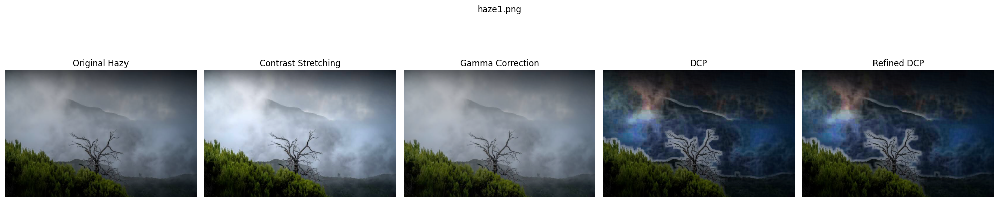

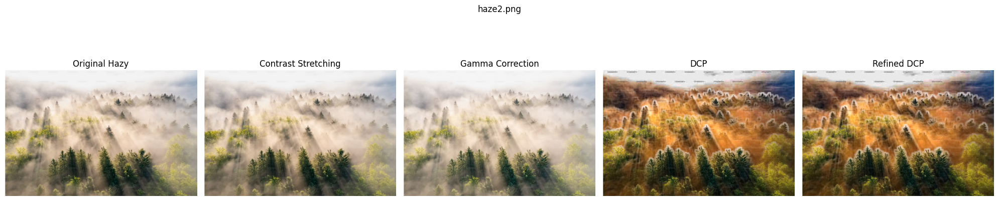

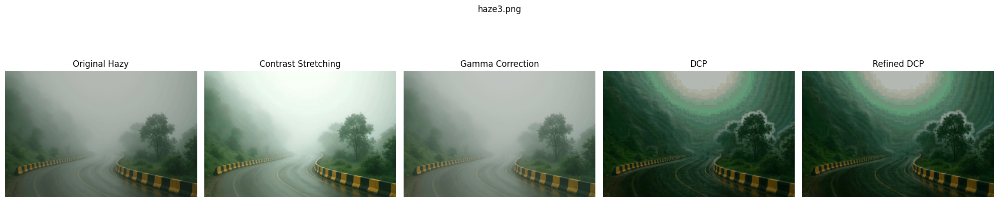

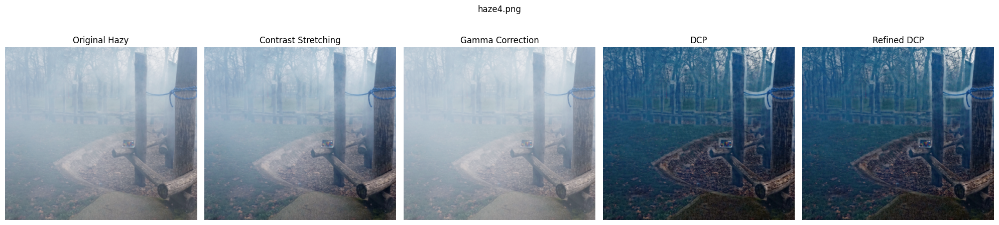

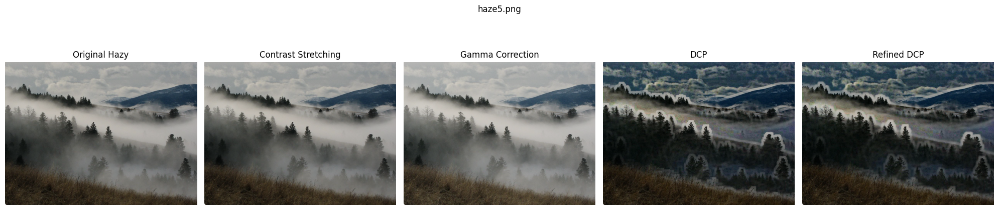

All comparison figures saved.


In [39]:
import matplotlib.pyplot as plt

for image_path in image_files:
    paths = [
        image_path,
        CONTRAST_DIR / f"{image_path.stem}_contrast.png",
        GAMMA_DIR / f"{image_path.stem}_gamma.png",
        DEHAZED_DIR / f"{image_path.stem}_dehazed.png",
        DEHAZED_DIR / f"{image_path.stem}_dehazed_refined.png"
    ]

    titles = [
        "Original Hazy",
        "Contrast Stretching",
        "Gamma Correction",
        "DCP",
        "Refined DCP"
    ]

    fig, axes = plt.subplots(1, 5, figsize=(20, 5))

    for ax, path, title in zip(axes, paths, titles):
        if path.exists():
            ax.imshow(Image.open(path).convert("RGB"))
            ax.set_title(title)
        else:
            ax.set_title(f"{title}: Missing")

        ax.axis("off")

    fig.suptitle(image_path.name)
    fig.tight_layout()

    figure_path = COMPARISON_DIR / f"{image_path.stem}_comparison.png"
    fig.savefig(figure_path, dpi=150, bbox_inches="tight")
    plt.show()
    plt.close(fig)

print("All comparison figures saved.")

In [40]:
import time
import csv
import numpy as np
from PIL import Image
from pathlib import Path

PROJECT_DIR = Path("/content/drive/MyDrive/ClearSight_Project")
HAZY_DIR = PROJECT_DIR / "data" / "hazy"
ATMOS_DIR = PROJECT_DIR / "results" / "atmospheric_light"
TIME_CSV = PROJECT_DIR / "results" / "metrics" / "processing_times.csv"

with open(ATMOS_DIR / "atmospheric_light_values.csv", "r", newline="") as file:
    atmospheric_values = {
        row["Image"]: np.array([
            float(row["Atmospheric_R"]),
            float(row["Atmospheric_G"]),
            float(row["Atmospheric_B"])
        ])
        for row in csv.DictReader(file)
    }

image_files = sorted([
    p for p in HAZY_DIR.iterdir()
    if p.suffix.lower() in [".jpg", ".jpeg", ".png", ".bmp"]
])

timing_rows = []

for image_path in image_files:
    image = np.asarray(
        Image.open(image_path).convert("RGB"),
        dtype=np.float64
    ) / 255.0

    A = atmospheric_values[image_path.name]

    start = time.perf_counter()
    contrast_stretch(image)
    contrast_time = time.perf_counter() - start

    start = time.perf_counter()
    gamma_correction(image, gamma=0.8)
    gamma_time = time.perf_counter() - start

    start = time.perf_counter()
    dark = calculate_dark_channel(image, window_size=15)
    A_test = estimate_atmospheric_light(image, dark)
    transmission = estimate_transmission(image, A_test, omega=0.95, window_size=15)
    reconstruct_dehazed_image(image, A_test, transmission, t0=0.1)
    dcp_time = time.perf_counter() - start

    start = time.perf_counter()
    refined = refine_transmission(transmission, window_size=5)
    reconstruct_dehazed_image(image, A_test, refined, t0=0.1)
    refinement_time = time.perf_counter() - start

    timing_rows.extend([
        [image_path.name, "Contrast Stretching", contrast_time],
        [image_path.name, "Gamma Correction", gamma_time],
        [image_path.name, "DCP Pipeline", dcp_time],
        [image_path.name, "DCP with Refinement", dcp_time + refinement_time]
    ])

TIME_CSV.parent.mkdir(parents=True, exist_ok=True)

with open(TIME_CSV, "w", newline="") as file:
    writer = csv.writer(file)
    writer.writerow(["Image", "Method", "Processing_Time_Seconds"])
    writer.writerows(timing_rows)

print("Processing times saved:", TIME_CSV)
print("Images measured:", len(image_files))

Processing times saved: /content/drive/MyDrive/ClearSight_Project/results/metrics/processing_times.csv
Images measured: 5


In [42]:
import pandas as pd

PROJECT_DIR = "/content/drive/MyDrive/ClearSight_Project"
file_path = f"{PROJECT_DIR}/results/metrics/processing_times.csv"

df = pd.read_csv(file_path)
display(df)

print("Total measurements:", len(df))
print("Methods:", df["Method"].unique())
print("Images:", df["Image"].nunique())

,Image,Method,Processing_Time_Seconds
0,haze1.png,Contrast Stretching,0.008054
1,haze1.png,Gamma Correction,0.027765
2,haze1.png,DCP Pipeline,0.254198
3,haze1.png,DCP with Refinement,0.277616
4,haze2.png,Contrast Stretching,0.016284
5,haze2.png,Gamma Correction,0.058878
6,haze2.png,DCP Pipeline,0.603143
7,haze2.png,DCP with Refinement,0.653388
8,haze3.png,Contrast Stretching,0.005465
9,haze3.png,Gamma Correction,0.028292


Total measurements: 20
Methods: ['Contrast Stretching' 'Gamma Correction' 'DCP Pipeline'
 'DCP with Refinement']
Images: 5


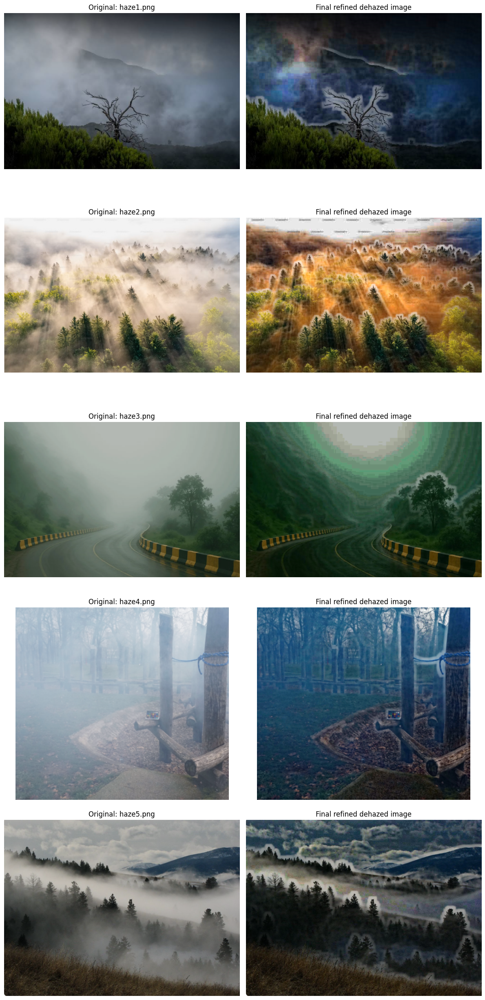

In [43]:
from pathlib import Path
from PIL import Image
import matplotlib.pyplot as plt

PROJECT_DIR = Path("/content/drive/MyDrive/ClearSight_Project")
HAZY_DIR = PROJECT_DIR / "data" / "hazy"
DEHAZED_DIR = PROJECT_DIR / "results" / "dehazed"

image_files = sorted([
    p for p in HAZY_DIR.iterdir()
    if p.suffix.lower() in [".jpg", ".jpeg", ".png", ".bmp"]
])

fig, axes = plt.subplots(len(image_files), 2, figsize=(12, 5 * len(image_files)))

for i, image_path in enumerate(image_files):
    original = Image.open(image_path).convert("RGB")
    output_path = DEHAZED_DIR / f"{image_path.stem}_dehazed_refined.png"

    axes[i, 0].imshow(original)
    axes[i, 0].set_title(f"Original: {image_path.name}")
    axes[i, 0].axis("off")

    if output_path.exists():
        dehazed = Image.open(output_path).convert("RGB")
        axes[i, 1].imshow(dehazed)
        axes[i, 1].set_title("Final refined dehazed image")
    else:
        axes[i, 1].text(0.5, 0.5, "Output image not found", ha="center", va="center")
        axes[i, 1].set_title("Missing output")

    axes[i, 1].axis("off")

plt.tight_layout()
plt.show()